# NLP Lab Task 04 — Text Preprocessing & Edit Distance
**Name:** Furqan  |  **Roll No:** SP24-BDS-014  |  **Course:** AIC365 Natural Language Processing

Tasks covered: 1) Lowercasing · 2) Noise removal · 3) Stop-words · 4) Risks of stop-word removal · 5) Porter stemmer ·
6) Lemmatization vs stemming · 7) Full preprocessing pipeline · 8) Levenshtein distance · 9) Spelling correction

In [12]:
# Run once (uncomment if you are on Colab / a fresh environment)
!pip install -q nltk spacy scikit-learn matplotlib pandas
!python -m spacy download en_core_web_sm

import re, time, string, math
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

for pkg in ["stopwords", "movie_reviews", "brown", "punkt", "punkt_tab", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
print("Setup done")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 33.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Setup done


---
# Task 1: Lowercasing Basics and Its Drawbacks

In [13]:
corpus1 = [
    "Apple released a new iPhone yesterday.",
    "I ate an apple and an orange for lunch.",
    "APPLE shares rose sharply after the announcement.",
    "The US government announced new trade rules.",
    "Please give us more time to finish the work.",
    "Bush was a president, but a bush is also a plant in my garden.",
    "Turkey is a beautiful country to visit in summer.",
    "We cooked a turkey for Thanksgiving dinner.",
    "May is a pleasant month, and it may rain today.",
    "Will Smith will attend the event tomorrow.",
    "Python is a popular language; a python is also a snake.",
    "The WHO issued a warning, but who will listen?",
]

def simple_tokens(text):
    return re.findall(r"[A-Za-z]+(?:'[a-z]+)?", text)

tokens_orig  = [t for s in corpus1 for t in simple_tokens(s)]
tokens_lower = [t.lower() for t in tokens_orig]

print("Tokens before lowercasing :", len(tokens_orig))
print("Vocabulary BEFORE lowercasing:", len(set(tokens_orig)))
print("Vocabulary AFTER  lowercasing:", len(set(tokens_lower)))
print("Reduction:", len(set(tokens_orig)) - len(set(tokens_lower)), "types merged")

# which words collapsed together?
groups = {}
for t in set(tokens_orig):
    groups.setdefault(t.lower(), set()).add(t)
print("\nForms merged by lowercasing:")
for k, v in groups.items():
    if len(v) > 1:
        print(f"  {sorted(v)} -> '{k}'")

Tokens before lowercasing : 105
Vocabulary BEFORE lowercasing: 79
Vocabulary AFTER  lowercasing: 69
Reduction: 10 types merged

Forms merged by lowercasing:
  ['Will', 'will'] -> 'will'
  ['APPLE', 'Apple', 'apple'] -> 'apple'
  ['The', 'the'] -> 'the'
  ['May', 'may'] -> 'may'
  ['US', 'us'] -> 'us'
  ['Turkey', 'turkey'] -> 'turkey'
  ['Bush', 'bush'] -> 'bush'
  ['WHO', 'who'] -> 'who'
  ['Python', 'python'] -> 'python'


### Three examples where lowercasing creates ambiguity
| Original | After lowercasing | Problem |
|---|---|---|
| **US** (country) vs **us** (pronoun) | `us` / `us` | The country name and the pronoun become the same token. |
| **Apple** (company) vs **apple** (fruit) | `apple` / `apple` | Company and fruit cannot be told apart. |
| **WHO** (organisation) vs **who** (question word) | `who` / `who` | An organisation becomes an ordinary stop-word. |

(Also: *Bush/bush*, *Turkey/turkey*, *May/may*, *Will/will*, *Python/python* in the corpus above.)

In [14]:
for pair in [("US", "us"), ("Apple", "apple"), ("WHO", "who")]:
    print(pair, "->", [p.lower() for p in pair], "| identical after lowercasing:", pair[0].lower() == pair[1].lower())

('US', 'us') -> ['us', 'us'] | identical after lowercasing: True
('Apple', 'apple') -> ['apple', 'apple'] | identical after lowercasing: True
('WHO', 'who') -> ['who', 'who'] | identical after lowercasing: True


### Which NLP tasks can be harmed by lowercasing?
**Named Entity Recognition (NER)** is harmed the most: capitalisation is one of the strongest clues that a word is a
name (*Apple*, *Bush*, *US*, *WHO*), so lowercasing removes the main signal and also creates confusion with common words.
**Sentiment analysis** can lose emphasis: `GREAT!!!` is more intense than `great`, and ALL-CAPS often marks shouting or anger.
**Search / information retrieval** can return wrong results, e.g. a query for `US` (the country) also matches the pronoun `us`,
and `Apple` the company is mixed with the fruit. On the other hand, lowercasing *helps* by shrinking the vocabulary and
making `The` / `the` the same word, so for topic classification or simple search it is usually safe and useful.

---
# Task 2: Noise Removal Pipeline

In [15]:
noisy = [
    "Loving the new #Python3 release!!! 😍 Check https://python.org/downloads  @guido_vr",
    "<p>Breaking: <b>Stocks</b> fall 5% today</p> read more at http://news.example.com/a?id=1&x=2",
    "@john_doe thx 4 the help!!!   See u   tomorrow 😊 #grateful",
    "I paid $100 for the C++ course... totally worth it!!! #coding @udemy",
    "<div class='review'>Great phone, battery lasts 2 days. 5/5 stars ⭐⭐⭐⭐⭐</div>",
    "RT @newsbot: Heavy rain expected in #Islamabad tonight 🌧️ https://t.co/abc123",
    "Worst   service   ever!!! 😡😡 Never   ordering   again... www.badshop.com",
    "Email me at test.user@mail.com or call 0300-1234567 ASAP!!!",
    "<br>Visit <a href='https://example.org'>our site</a> for 50% OFF!!!<br>",
    "#NLP is fun :) learning tokenization & stemming w/ NLTK @nltk_org",
    "The U.S. economy grew 3.5% in Q2, says @Reuters https://reut.rs/xyz",
    "Just watched #Avengers 🎬🍿 amazing!!!   10/10 would recommend",
    "   Leading   and trailing   spaces   everywhere   ",
    "<h1>Sale!</h1> Buy 1 get 1 free!!! Visit http://shop.pk/sale NOW 🔥🔥",
    "My code in C# and C++ finally works 🎉 #happy #dev @stackoverflow",
    "Price dropped from $1,299.99 to $999!!! Don't miss out :( #deal",
]
print(len(noisy), "noisy entries")

16 noisy entries


In [16]:
# One regex function per noise type
URL_RE     = re.compile(r"(?:https?://|www\.)\S+")
HTML_RE    = re.compile(r"<[^>]+>")
MENTION_RE = re.compile(r"(?<!\w)@\w+")
HASHTAG_RE = re.compile(r"(?<!\w)#(\w+)")
EMOJI_RE   = re.compile("[\U0001F300-\U0001FAFF\U0001F000-\U0001F2FF\u2600-\u27BF\u2B50\u2B55\uFE0F\u200d]+")
PUNCT_RE   = re.compile(r"[^\w\s]")
WS_RE      = re.compile(r"\s+")

def remove_urls(t):        return URL_RE.sub(" ", t)
def remove_html(t):        return HTML_RE.sub(" ", t)
def remove_mentions(t):    return MENTION_RE.sub(" ", t)
def handle_hashtags(t):    return HASHTAG_RE.sub(r"\1", t)          # keep the word, drop '#'
def remove_emojis(t):      return EMOJI_RE.sub(" ", t)
def remove_punct(t):       return PUNCT_RE.sub("", t)
def normalize_ws(t):       return WS_RE.sub(" ", t).strip()

STEPS = {
    "html": remove_html, "url": remove_urls, "mention": remove_mentions,
    "hashtag": handle_hashtags, "emoji": remove_emojis,
    "punct": remove_punct, "ws": normalize_ws,
}
DEFAULT_ORDER = ["html", "url", "mention", "hashtag", "emoji", "punct", "ws"]

def clean_text(text, order=DEFAULT_ORDER):
    for step in order:
        text = STEPS[step](text)
    return text

for t in noisy[:3]:
    print("RAW  :", t)
    print("CLEAN:", clean_text(t), "\n")

RAW  : Loving the new #Python3 release!!! 😍 Check https://python.org/downloads  @guido_vr
CLEAN: Loving the new Python3 release Check 

RAW  : <p>Breaking: <b>Stocks</b> fall 5% today</p> read more at http://news.example.com/a?id=1&x=2
CLEAN: Breaking Stocks fall 5 today read more at 

RAW  : @john_doe thx 4 the help!!!   See u   tomorrow 😊 #grateful
CLEAN: thx 4 the help See u tomorrow grateful 



### Does the order of steps matter?  Yes.
Below the *punctuation* step is moved to the front. It destroys `<`, `>`, `://`, `@`, `#`, so the later HTML / URL / mention
regexes no longer recognise their patterns and leave junk behind.

In [17]:
bad_order = ["punct", "html", "url", "mention", "hashtag", "emoji", "ws"]

diff_rows = []
for t in noisy:
    a, b = clean_text(t, DEFAULT_ORDER), clean_text(t, bad_order)
    if a != b:
        diff_rows.append({"Raw": t, "Good order": a, "Bad order (punct first)": b})

print(f"{len(diff_rows)} of {len(noisy)} entries change when the order changes\n")
pd.DataFrame(diff_rows).head(5)

12 of 16 entries change when the order changes



,Raw,Good order,Bad order (punct first)
0,Loving the new #Python3 release!!! 😍 Check https://python.org/downloads @guido_vr,Loving the new Python3 release Check,Loving the new Python3 release Check httpspythonorgdownloads guido_vr
1,<p>Breaking: <b>Stocks</b> fall 5% today</p> read more at http://news.example.com/a?id=1&x=2,Breaking Stocks fall 5 today read more at,pBreaking bStocksb fall 5 todayp read more at httpnewsexamplecomaid1x2
2,@john_doe thx 4 the help!!! See u tomorrow 😊 #grateful,thx 4 the help See u tomorrow grateful,john_doe thx 4 the help See u tomorrow grateful
3,I paid $100 for the C++ course... totally worth it!!! #coding @udemy,I paid 100 for the C course totally worth it coding,I paid 100 for the C course totally worth it coding udemy
4,"<div class='review'>Great phone, battery lasts 2 days. 5/5 stars ⭐⭐⭐⭐⭐</div>",Great phone battery lasts 2 days 55 stars,div classreviewGreat phone battery lasts 2 days 55 stars div


### Before / After table (5 examples) and over-cleaning

In [18]:
idx = [3, 10, 15, 14, 1]       # entries containing $100, 3.5%, $1,299.99, C++/C#, HTML
table = pd.DataFrame({
    "Before": [noisy[i] for i in idx],
    "After clean_text()": [clean_text(noisy[i]) for i in idx],
})
table

,Before,After clean_text()
0,I paid $100 for the C++ course... totally worth it!!! #coding @udemy,I paid 100 for the C course totally worth it coding
1,"The U.S. economy grew 3.5% in Q2, says @Reuters https://reut.rs/xyz",The US economy grew 35 in Q2 says
2,"Price dropped from $1,299.99 to $999!!! Don't miss out :( #deal",Price dropped from 129999 to 999 Dont miss out deal
3,My code in C# and C++ finally works 🎉 #happy #dev @stackoverflow,My code in C and C finally works happy dev
4,<p>Breaking: <b>Stocks</b> fall 5% today</p> read more at http://news.example.com/a?id=1&x=2,Breaking Stocks fall 5 today read more at


**Where cleaning went too far (over-cleaning):**
* `C++` → `C` and `C#` → `C`: the programming language names lose their meaning (`C`, `C++`, `C#` become identical).
* `$100` → `100`, `$1,299.99` → `129999`: the currency symbol and decimal point disappear, so the price becomes a wrong number.
* `3.5%` → `35`, `5%` → `5`, `5/5 stars` → `55 stars`: percentages, decimals and ratings are damaged.
* `U.S.` → `US` (merges with the pronoun `us` after lowercasing), `Don't` → `Dont`, emails / phone numbers are broken.

A safer version below protects such patterns before removing punctuation.

In [19]:
PROTECT_RE = re.compile(r"(C\+\+|C#|\$\d[\d,]*(?:\.\d+)?|\d+(?:\.\d+)?%|\w+'\w+)")

def remove_punct_safe(t):
    parts = PROTECT_RE.split(t)          # odd positions = protected tokens
    return "".join(p if i % 2 else PUNCT_RE.sub("", p) for i, p in enumerate(parts))

def clean_text_safe(text):
    for step in ["html", "url", "mention", "hashtag", "emoji"]:
        text = STEPS[step](text)
    return normalize_ws(remove_punct_safe(text))

pd.DataFrame({
    "Before": [noisy[i] for i in idx],
    "Aggressive": [clean_text(noisy[i]) for i in idx],
    "Safe (protected)": [clean_text_safe(noisy[i]) for i in idx],
})

,Before,Aggressive,Safe (protected)
0,I paid $100 for the C++ course... totally worth it!!! #coding @udemy,I paid 100 for the C course totally worth it coding,I paid $100 for the C++ course totally worth it coding
1,"The U.S. economy grew 3.5% in Q2, says @Reuters https://reut.rs/xyz",The US economy grew 35 in Q2 says,The US economy grew 3.5% in Q2 says
2,"Price dropped from $1,299.99 to $999!!! Don't miss out :( #deal",Price dropped from 129999 to 999 Dont miss out deal,"Price dropped from $1,299.99 to $999 Don't miss out deal"
3,My code in C# and C++ finally works 🎉 #happy #dev @stackoverflow,My code in C and C finally works happy dev,My code in C# and C++ finally works happy dev
4,<p>Breaking: <b>Stocks</b> fall 5% today</p> read more at http://news.example.com/a?id=1&x=2,Breaking Stocks fall 5 today read more at,Breaking Stocks fall 5% today read more at


---
# Task 3: Stop-Word Removal and Its Effect on Vocabulary

In [20]:
from nltk.corpus import stopwords, movie_reviews
stop_nltk = set(stopwords.words("english"))
print("First 20 stop-words:", stopwords.words("english")[:20])
print("Total size of NLTK English stop-word list:", len(stop_nltk))

First 20 stop-words: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']
Total size of NLTK English stop-word list: 198


In [21]:
# Dataset: 500 movie reviews (250 neg + 250 pos), sentence-tokenised by NLTK
neg_ids = movie_reviews.fileids("neg")[:250]
pos_ids = movie_reviews.fileids("pos")[:250]
sentences = []
for fid in neg_ids + pos_ids:
    for sent in movie_reviews.sents(fid):
        toks = [w.lower() for w in sent if w.isalpha()]
        if toks:
            sentences.append(toks)

def stats(sents):
    flat = [w for s in sents for w in s]
    non_empty = [s for s in sents if s]
    return {"Tokens": len(flat), "Vocabulary": len(set(flat)),
            "Sentences": len(non_empty),
            "Avg sentence length": round(len(flat) / len(non_empty), 2)}

sentences_nsw = [[w for w in s if w not in stop_nltk] for s in sentences]
comp = pd.DataFrame([stats(sentences), stats(sentences_nsw)], index=["Before removal", "After removal"])
comp

,Tokens,Vocabulary,Sentences,Avg sentence length
Before removal,316579,21410,16208,19.53
After removal,167672,21261,16039,10.45


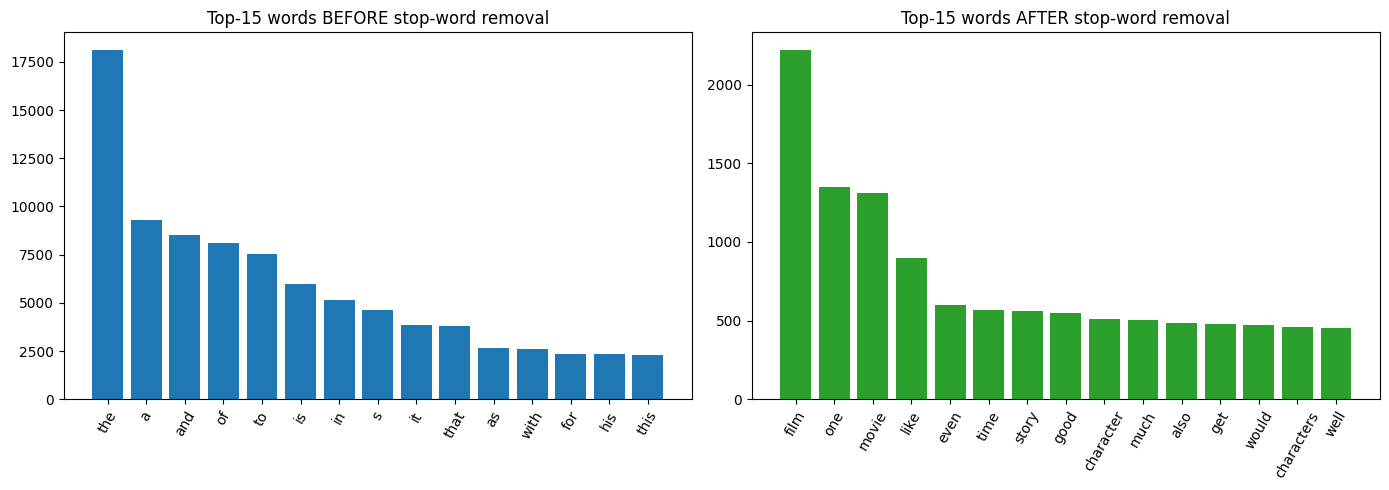

In [22]:
# Top-15 words before / after
before_counts = Counter(w for s in sentences for w in s)
after_counts  = Counter(w for s in sentences_nsw for w in s)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, cnt, title, col in [(ax[0], before_counts, "Top-15 words BEFORE stop-word removal", "tab:blue"),
                           (ax[1], after_counts,  "Top-15 words AFTER stop-word removal",  "tab:green")]:
    words, freqs = zip(*cnt.most_common(15))
    a.bar(words, freqs, color=col)
    a.set_title(title); a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

**Observation:** removal cuts the **token count by about 47%** and halves the **average sentence length** (19.5 → 10.5 words), but the
**vocabulary shrinks only slightly** (21,410 → 21,261), because stop-words are few *types* that repeat very often.
Before removal the top-15 words are all function words (`the`, `a`, `and`, `of`, `to`, `is`...), which tell us nothing about the topic.
After removal content words appear (`film`, `one`, `movie`, `like`, `story`, `good`...), but generic domain words such as
*film / movie / one* still dominate. This motivates a **custom stop-word list**.

In [23]:
# Custom stop-word list: ADD 10+ domain words, REMOVE 10 words that carry sentiment/negation
add_words = {
    "movie":  "appears in almost every review, carries no polarity information",
    "film":   "same as 'movie' (domain word)",
    "movies": "plural form of the domain word",
    "films":  "plural form of the domain word",
    "one":    "very frequent filler ('one of the best'), no content",
    "would":  "modal filler, extremely frequent in reviews",
    "also":   "discourse filler",
    "even":   "discourse filler",
    "get":    "generic verb with low information",
    "much":   "quantifier filler",
    "could":  "modal filler",
}
remove_words = {
    "not":     "negation - flips sentiment",
    "no":      "negation",
    "nor":     "negation",
    "very":    "intensifier ('very good' vs 'good')",
    "too":     "intensifier ('too long')",
    "against": "carries opinion/direction ('against the plot')",
    "but":     "contrast marker, often precedes the real opinion",
    "only":    "restricts meaning ('only good')",
    "few":     "quantifier with polarity ('few laughs')",
    "most":    "superlative marker ('most boring')",
}
custom_stop = (stop_nltk | set(add_words)) - set(remove_words)
print("NLTK size:", len(stop_nltk), "-> custom size:", len(custom_stop))
print("\nADDED:");   [print(f"  + {w:7s} {why}") for w, why in add_words.items()]
print("\nREMOVED:"); [print(f"  - {w:8s} {why}") for w, why in remove_words.items()]

sentences_custom = [[w for w in s if w not in custom_stop] for s in sentences]
pd.DataFrame([stats(sentences), stats(sentences_nsw), stats(sentences_custom)], index=["Before", "NLTK list", "Custom list"])

NLTK size: 198 -> custom size: 199

ADDED:
  + movie   appears in almost every review, carries no polarity information
  + film    same as 'movie' (domain word)
  + movies  plural form of the domain word
  + films   plural form of the domain word
  + one     very frequent filler ('one of the best'), no content
  + would   modal filler, extremely frequent in reviews
  + also    discourse filler
  + even    discourse filler
  + get     generic verb with low information
  + much    quantifier filler
  + could   modal filler

REMOVED:
  - not      negation - flips sentiment
  - no       negation
  - nor      negation
  - very     intensifier ('very good' vs 'good')
  - too      intensifier ('too long')
  - against  carries opinion/direction ('against the plot')
  - but      contrast marker, often precedes the real opinion
  - only     restricts meaning ('only good')
  - few      quantifier with polarity ('few laughs')
  - most     superlative marker ('most boring')


,Tokens,Vocabulary,Sentences,Avg sentence length
Before,316579,21410,16208,19.53
NLTK list,167672,21261,16039,10.45
Custom list,165415,21260,16048,10.31


---
# Task 4: Risks of Stop-Word Removal (Sentiment, MT, Chatbots)
## Part 1 — Sentiment and negation

In [24]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
aggressive = stop_nltk | set(ENGLISH_STOP_WORDS)      # NLTK ∪ sklearn (contains 'never', 'nothing', ...)
print("'never' in NLTK list:", "never" in stop_nltk, "| in aggressive list:", "never" in aggressive)

POS_WORDS = {"good", "happy", "great", "helpful", "love", "amazing", "fast", "excellent"}
NEG_WORDS = {"bad", "sad", "terrible", "problem", "slow", "hate", "poor", "late"}
NEGATORS  = {"not", "no", "never", "nobody", "nothing", "none", "neither", "nor", "cannot", "hardly"}

def tok(s): return re.findall(r"[a-z]+(?:'[a-z]+)?", s.lower())

def sentiment(tokens):
    score = 0
    for i, t in enumerate(tokens):
        s = 1 if t in POS_WORDS else -1 if t in NEG_WORDS else 0
        if s and any((tokens[j] in NEGATORS or tokens[j].endswith("n't")) for j in range(max(0, i - 2), i)):
            s = -s                                    # negation flips polarity
        score += s
    return "positive" if score > 0 else "negative" if score < 0 else "neutral"

def remove_sw(text, sw): return [w for w in tok(text) if w not in sw]

neg_sents = [
    "The movie was not good.",
    "I am never happy with this service.",
    "There is no problem with the delivery.",
    "The staff was not helpful at all.",
    "I don't hate this phone.",
]
rows = []
for s in neg_sents:
    orig = sentiment(tok(s))
    r1, r2 = remove_sw(s, stop_nltk), remove_sw(s, aggressive)
    rows.append({"Sentence": s, "Original": orig,
                 "After NLTK removal": " ".join(r1), "NLTK sentiment": sentiment(r1),
                 "After aggressive removal": " ".join(r2), "Aggr. sentiment": sentiment(r2),
                 "Flipped?": "YES" if sentiment(r1) != orig or sentiment(r2) != orig else "no"})
pd.DataFrame(rows)

'never' in NLTK list: False | in aggressive list: True


,Sentence,Original,After NLTK removal,NLTK sentiment,After aggressive removal,Aggr. sentiment,Flipped?
0,The movie was not good.,negative,movie good,positive,movie good,positive,YES
1,I am never happy with this service.,negative,never happy service,negative,happy service,positive,YES
2,There is no problem with the delivery.,positive,problem delivery,negative,problem delivery,negative,YES
3,The staff was not helpful at all.,negative,staff helpful,positive,staff helpful,positive,YES
4,I don't hate this phone.,positive,hate phone,negative,hate phone,negative,YES


**Result:** the negation words (`not`, `no`, `don't`, and `never` in the aggressive list) are removed, so
*"not good"* becomes *"good"* and *"no problem"* becomes *"problem"* — the sentiment flips.

## Part 2 — Machine translation (English → Urdu)
I removed NLTK stop-words from 3 sentences (code below) and translated both versions into Urdu.
The Urdu column is my translation; **please re-check / paste the output of Google Translate** for your own submission.

In [25]:
mt_sents = [
    "She is not at home today.",
    "We did not receive the money from the bank.",
    "The doctor said that he should not take this medicine.",
]
for s in mt_sents:
    print(f"ORIGINAL: {s}\nREDUCED : {' '.join(remove_sw(s, stop_nltk))}\n")

ORIGINAL: She is not at home today.
REDUCED : home today

ORIGINAL: We did not receive the money from the bank.
REDUCED : receive money bank

ORIGINAL: The doctor said that he should not take this medicine.
REDUCED : doctor said take medicine



| English (original) | Urdu (original) | Reduced English | Urdu (reduced) | Meaning distorted? |
|---|---|---|---|---|
| She is not at home today. | وہ آج گھر پر نہیں ہے۔ | home today | گھر آج | Yes — subject, verb and **negation** are lost; the sentence is no longer grammatical. |
| We did not receive the money from the bank. | ہمیں بینک سے رقم موصول نہیں ہوئی۔ | receive money bank | رقم بینک موصول کریں | Yes — a statement ("not received") becomes a command/neutral phrase. |
| The doctor said that he should not take this medicine. | ڈاکٹر نے کہا کہ اسے یہ دوا نہیں لینی چاہیے۔ | doctor said take medicine | ڈاکٹر نے دوا لینے کو کہا | **Dangerous** — the meaning is reversed ("should not take" → "said to take"). |

**Conclusion:** MT needs the full grammar (pronouns, auxiliaries, negation, prepositions). Removing stop-words destroys the structure that
the target language needs, so stop-word removal should **never** be applied before translation.

## Part 3 — Chatbot intent

In [26]:
queries = [
    "How to not be charged for the subscription?",
    "What is the status of my order?",
    "I can't log in to my account.",
    "Why was my payment not received?",
    "How do I cancel my order before it is shipped?",
]
pd.DataFrame({"Query": queries,
              "After NLTK removal": [" ".join(remove_sw(q, stop_nltk)) for q in queries],
              "After aggressive removal": [" ".join(remove_sw(q, aggressive)) for q in queries]})

,Query,After NLTK removal,After aggressive removal
0,How to not be charged for the subscription?,charged subscription,charged subscription
1,What is the status of my order?,status order,status order
2,I can't log in to my account.,can't log account,can't log account
3,Why was my payment not received?,payment received,payment received
4,How do I cancel my order before it is shipped?,cancel order shipped,cancel order shipped


**Observations:**
* *"How to **not** be charged..."* → `charged subscription`: the user wants to **avoid** a charge, but the reduced text looks like a billing question.
* *"What is the status of my order?"* → `status order`: the question word (`what`) and the ownership (`my`) are gone, so a "track order" intent becomes ambiguous.
* *"Why was my payment not received?"* → `payment received`: it now reads as a **confirmation** instead of a complaint.
* *"before it is shipped"* → `cancel order shipped`: the timing condition (`before`) disappears, so we can't tell "cancel before shipping" from "cancel after shipping".
* *"I can't log in..."* → `can't log account`: the contraction survives only because the list has no `can't` entry (while it does contain `don't`, `didn't`...), a sign of how inconsistent such lists are.

## Part 4 — A safe stop-word strategy
Keep **negations, question words, modals, intensifiers/contrast words and temporal prepositions**; remove only the real function words.

In [27]:
KEEP = {"not", "no", "nor", "never", "nobody", "nothing", "none", "neither", "cannot", "hardly", "nowhere",
        "but", "however", "very", "too", "against", "only", "few", "most", "more", "less",
        "how", "what", "why", "when", "where", "who", "which", "whom",
        "can", "cant", "could", "should", "would", "must", "will",
        "before", "after", "off", "out", "up", "down", "over", "under", "again"}
safe_stop = {w for w in aggressive if w not in KEEP and not w.endswith("n't")}
print("Aggressive:", len(aggressive), "words  ->  Safe list:", len(safe_stop), "words")

rows = []
for s in neg_sents:
    r = remove_sw(s, safe_stop)
    rows.append({"Sentence": s, "Original": sentiment(tok(s)), "Safe-reduced": " ".join(r),
                 "Sentiment": sentiment(r), "Flipped?": "YES" if sentiment(r) != sentiment(tok(s)) else "no"})
display(pd.DataFrame(rows))

display(pd.DataFrame({"Query": queries, "Safe-reduced": [" ".join(remove_sw(q, safe_stop)) for q in queries]}))

Aggressive: 397 words  ->  Safe list: 335 words


,Sentence,Original,Safe-reduced,Sentiment,Flipped?
0,The movie was not good.,negative,movie not good,negative,no
1,I am never happy with this service.,negative,never happy service,negative,no
2,There is no problem with the delivery.,positive,no problem delivery,positive,no
3,The staff was not helpful at all.,negative,staff not helpful,negative,no
4,I don't hate this phone.,positive,don't hate phone,positive,no


,Query,Safe-reduced
0,How to not be charged for the subscription?,how not charged subscription
1,What is the status of my order?,what status order
2,I can't log in to my account.,can't log account
3,Why was my payment not received?,why payment not received
4,How do I cancel my order before it is shipped?,how cancel order before shipped


With the safe list, **no sentiment flips** and the chatbot queries keep their negation, question word and timing words.

---
# Task 5: Hands-On with the Porter Stemmer

In [28]:
from nltk.stem import PorterStemmer, SnowballStemmer
porter, snowball = PorterStemmer(), SnowballStemmer("english")

words5 = ["running", "runs", "ran", "studies", "studying", "happily", "happiness", "generalization", "generalize",
          "general", "generate", "generic", "better", "best", "was", "were", "caresses", "ponies", "flies", "easily",
          "organization", "organize", "organ", "university", "universe", "universal", "data", "datum", "alumni",
          "alumnus", "analysis", "analyses", "argument", "arguing", "argues", "wolves", "wolf", "children", "child",
          "flying", "fly", "relational", "rational", "hopping", "hoping", "hopeful", "mice", "mouse", "communication",
          "communicate", "community", "common", "meeting"]
print(len(words5), "words")

# Manual judgement: is the stem a sensible shared root that groups the word with its family and
# does NOT merge it with an unrelated word?
incorrect = {
    "ran": "irregular verb: not linked to 'run'",
    "happily": "'happili' is not a root and differs from 'happi' (happiness)",
    "easily": "'easili' is not a root",
    "was": "'wa' is a broken stem",
    "better": "not linked to 'good'",
    "best": "not linked to 'good'",
    "generalization": "merged with generate/generic (over-stemming)",
    "generalize": "merged with generate/generic (over-stemming)",
    "general": "merged with generate/generic (over-stemming)",
    "generate": "merged with general/generic (over-stemming)",
    "generic": "merged with general/generate (over-stemming)",
    "organization": "merged with 'organ' (body part) - over-stemming",
    "organize": "merged with 'organ' - over-stemming",
    "organ": "merged with 'organization' - over-stemming",
    "university": "merged with universe/universal - over-stemming",
    "universe": "merged with university - over-stemming",
    "universal": "merged with university - over-stemming",
    "datum": "not linked to 'data' (under-stemming)",
    "alumnus": "'alumnu' is not a root",
    "analysis": "'analysi' is not a root, not linked to 'analyses'",
    "analyses": "not linked to 'analysis' (under-stemming)",
    "wolves": "'wolv' not linked to 'wolf' (under-stemming)",
    "mice": "not linked to 'mouse' (under-stemming)",
    "mouse": "not linked to 'mice' (under-stemming)",
    "children": "not linked to 'child' (under-stemming)",
    "rational": "'ration' is a different word (ration)",
    "communication": "'commun' collides with 'community/common'",
    "communicate": "'commun' collides with 'community/common'",
    "community": "merged with communicate/common - over-stemming",
    "common": "merged with community/communicate - over-stemming",
    "argument": "'argument' is not linked to 'argu' (arguing/argues) - under-stemming",
    "were": "irregular form: not linked to 'be'",
}
# (A stem such as "studi" is fine: it need not be a real word as long as it groups the word family correctly.)
rows = []
for w in words5:
    verdict = "Incorrect" if w in incorrect else "Correct"
    rows.append({"Word": w, "Stem": porter.stem(w), "Correct/Incorrect": verdict,
                 "Reason": incorrect.get(w, "")})
df5 = pd.DataFrame(rows)
df5

53 words


,Word,Stem,Correct/Incorrect,Reason
0,running,run,Correct,
1,runs,run,Correct,
2,ran,ran,Incorrect,irregular verb: not linked to 'run'
3,studies,studi,Correct,
4,studying,studi,Correct,
5,happily,happili,Incorrect,'happili' is not a root and differs from 'happi' (happiness)
6,happiness,happi,Correct,
7,generalization,gener,Incorrect,merged with generate/generic (over-stemming)
8,generalize,gener,Incorrect,merged with generate/generic (over-stemming)
9,general,gener,Incorrect,merged with generate/generic (over-stemming)


In [29]:
print("Correct:", (df5["Correct/Incorrect"] == "Correct").sum(), "| Incorrect:", (df5["Correct/Incorrect"] == "Incorrect").sum())

# Over-stemming: different words that share one stem
by_stem = {}
for w in words5:
    by_stem.setdefault(porter.stem(w), []).append(w)
print("\nOVER-STEMMING (different meanings, same stem):")
for stem, ws in by_stem.items():
    if stem in {"univers", "gener", "organ", "commun"}:
        print(f"  {stem:8s} <- {ws}")

# Under-stemming: related words that end up with different stems
under = [("argue", "argument"), ("data", "datum"), ("alumni", "alumnus"), ("analysis", "analyses"), ("run", "ran"),
         ("mouse", "mice"), ("wolf", "wolves"), ("child", "children"), ("happy", "happiness")]
print("\nUNDER-STEMMING (related words, different stems):")
for a, b in under:
    if porter.stem(a) != porter.stem(b):
        print(f"  {a:9s}->{porter.stem(a):9s} | {b:10s}->{porter.stem(b)}")

Correct: 21 | Incorrect: 32

OVER-STEMMING (different meanings, same stem):
  gener    <- ['generalization', 'generalize', 'general', 'generate', 'generic']
  organ    <- ['organization', 'organize', 'organ']
  univers  <- ['university', 'universe', 'universal']
  commun   <- ['communication', 'communicate', 'community']

UNDER-STEMMING (related words, different stems):
  argue    ->argu      | argument  ->argument
  data     ->data      | datum     ->datum
  alumni   ->alumni    | alumnus   ->alumnu
  analysis ->analysi   | analyses  ->analys
  run      ->run       | ran       ->ran
  mouse    ->mous      | mice      ->mice
  wolf     ->wolf      | wolves    ->wolv
  child    ->child     | children  ->children


In [30]:
# Porter vs Snowball
diff = [(w, porter.stem(w), snowball.stem(w)) for w in words5 if porter.stem(w) != snowball.stem(w)]
print(f"{len(diff)} of {len(words5)} words differ\n")
pd.DataFrame(diff, columns=["Word", "Porter", "Snowball"])

10 of 53 words differ



,Word,Porter,Snowball
0,generalization,gener,general
1,generalize,gener,general
2,general,gener,general
3,generate,gener,generat
4,generic,gener,generic
5,was,wa,was
6,alumnus,alumnu,alumnus
7,communication,commun,communic
8,communicate,commun,communic
9,community,commun,communiti


**Observation:** Snowball (Porter2) is slightly more careful: it keeps `general`, `generic` and `generat(e)` apart (Porter merges them all into `gener`),
keeps `communic-`, and treats `was`, `alumnus` correctly. Porter is more aggressive, which causes more over-stemming.

---
# Task 6: Lemmatization (spaCy) vs. Stemming

In [31]:
import spacy
nlp = spacy.load("en_core_web_sm")

paragraph = (
    "The researchers were studying how children are learning languages better than adults. "
    "Running experiments was hard, and the mice in the lab had eaten the data cables. "
    "She studies linguistics while her friends are working on better translation systems. "
    "The universities were hosting meetings, and the teams had been analyzing thousands of sentences every day. "
    "Although the results were surprising, the scientists believed that the models would keep improving. "
    "Many students saw the new papers and said they could finally understand why machines make mistakes. "
    "Better datasets, careful testing and patient teachers have made the process easier than before. "
    "Everyone was very happy."
)
print("Word count:", len(paragraph.split()))

doc = nlp(paragraph)
tokens = [t for t in doc if t.is_alpha]
comp6 = pd.DataFrame({
    "Token": [t.text for t in tokens],
    "POS":   [t.pos_ for t in tokens],
    "Stem":  [porter.stem(t.text) for t in tokens],
    "Lemma": [t.lemma_ for t in tokens],
})
comp6.head(25)

Word count: 103


,Token,POS,Stem,Lemma
0,The,DET,the,the
1,researchers,NOUN,research,researcher
2,were,AUX,were,be
3,studying,VERB,studi,study
4,how,SCONJ,how,how
5,children,NOUN,children,child
6,are,AUX,are,be
7,learning,VERB,learn,learn
8,languages,NOUN,languag,language
9,better,ADJ,better,well


In [32]:
# Where lemmatization outperforms stemming
better = comp6[(comp6["Stem"] != comp6["Lemma"].str.lower()) & (comp6["Token"].str.lower() != comp6["Lemma"].str.lower())]
better = better.drop_duplicates(subset=["Token"]).reset_index(drop=True)
print(len(better), "words where the lemma differs from the surface form AND from the stem")
better

29 words where the lemma differs from the surface form AND from the stem


,Token,POS,Stem,Lemma
0,researchers,NOUN,research,researcher
1,were,AUX,were,be
2,studying,VERB,studi,study
3,children,NOUN,children,child
4,are,AUX,are,be
5,languages,NOUN,languag,language
6,better,ADJ,better,well
7,experiments,NOUN,experi,experiment
8,was,AUX,wa,be
9,mice,NOUN,mice,mouse


**Examples:** `was/were → be`, `saw → see`, `mice → mouse`, `children → child`, `studies → study`, `had → have`, `eaten → eat`, `better → well`.
A stemmer cannot do these: it produces `wa`, `saw`, `mice`, `children`, `studi`, `had`, `eaten`, `better`.

**Note:** the task example says `better → good`. spaCy's small model maps *better* to **`well`** (its lookup table), while WordNet gives
**`good`** when told that the word is an adjective (see the next cell). Either way, the lemmatizer links *better* to a different word, which a stemmer cannot.

### The role of the POS tag
The lemma depends on the part of speech. The same word form can have different lemmas.

In [33]:
for s in ["He saw the movie yesterday.", "She cut the wood with a saw.",
          "The meeting is at noon.", "We are meeting the client.",
          "This is better than that.", "She sings better now."]:
    print(f"{s:35s}", [(t.text, t.pos_, t.lemma_) for t in nlp(s) if t.text.lower() in {"saw", "meeting", "better"}])

He saw the movie yesterday.         [('saw', 'VERB', 'see')]
She cut the wood with a saw.        [('saw', 'NOUN', 'saw')]
The meeting is at noon.             [('meeting', 'NOUN', 'meeting')]
We are meeting the client.          [('meeting', 'VERB', 'meet')]
This is better than that.           [('better', 'ADJ', 'well')]
She sings better now.               [('better', 'ADV', 'well')]


`saw` is lemmatised to **see** when it is a verb but stays **saw** when it is a noun; `meeting` is **meet** (verb) vs **meeting** (noun).
The lemmatizer needs the POS tag to choose the right dictionary entry; a stemmer ignores POS completely.

In [34]:
# WordNet lemmatizer: the POS argument changes the answer ('a' = adjective, 'r' = adverb, 'v' = verb, 'n' = noun)
from nltk.stem import WordNetLemmatizer
wnl = WordNetLemmatizer()
for w, p in [("better", "a"), ("better", "r"), ("better", "v"), ("was", "v"), ("meeting", "v"), ("meeting", "n")]:
    print(f"lemmatize({w!r}, pos={p!r}) -> {wnl.lemmatize(w, pos=p)!r}")

lemmatize('better', pos='a') -> 'good'
lemmatize('better', pos='r') -> 'well'
lemmatize('better', pos='v') -> 'better'
lemmatize('was', pos='v') -> 'be'
lemmatize('meeting', pos='v') -> 'meet'
lemmatize('meeting', pos='n') -> 'meeting'


In [35]:
# Speed comparison on a larger text (paragraph repeated 100x)
big_text = (paragraph + " ") * 100
big_tokens = re.findall(r"[A-Za-z]+", big_text)
print("Tokens in test text:", len(big_tokens))

fresh_porter = PorterStemmer()
t0 = time.perf_counter()
stems = [fresh_porter.stem(w) for w in big_tokens]
t_stem = time.perf_counter() - t0

nlp_fast = spacy.load("en_core_web_sm", disable=["parser", "ner"])
t0 = time.perf_counter()
lemmas = [t.lemma_ for t in nlp_fast(big_text)]
t_lemma = time.perf_counter() - t0

print(f"Porter stemming : {t_stem:.3f} s")
print(f"spaCy lemmatize : {t_lemma:.3f} s  (includes tokenisation + POS tagging)")
print(f"Lemmatization is about {t_lemma / t_stem:.1f}x slower")

Tokens in test text: 10300
Porter stemming : 0.423 s
spaCy lemmatize : 2.515 s  (includes tokenisation + POS tagging)
Lemmatization is about 5.9x slower


**When to use which**
* **Stemming** — fast and simple; good for search engines / information retrieval and large-scale topic classification where
  recall matters and the stem does not need to be readable.
* **Lemmatization** — slower but accurate and readable; choose it for chatbots, question answering, sentiment analysis,
  machine translation and any task where the real dictionary form or the POS matters.

---
# Task 7: Full Preprocessing Pipeline

In [48]:
class Preprocessor:
    """lowercase -> noise removal -> tokenization -> stop-word removal -> stemming OR lemmatization"""

    def __init__(self, lowercase=True, remove_noise=True, stopwords=None, normalizer=None):
        assert normalizer in (None, "stem", "lemma")
        self.lowercase, self.remove_noise = lowercase, remove_noise
        self.stopwords, self.normalizer = stopwords, normalizer
        self._stemmer = PorterStemmer()
        self._stem_cache = {}
        self._nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"]) if normalizer == "lemma" else None

    def _clean(self, t):
        t = URL_RE.sub(" ", t); t = HTML_RE.sub(" ", t)
        t = MENTION_RE.sub(" ", t); t = EMOJI_RE.sub(" ", t)
        return t

    def _stem(self, w):
        if w not in self._stem_cache:
            self._stem_cache[w] = self._stemmer.stem(w)
        return self._stem_cache[w]

    def transform(self, docs):
        out = []
        for d in docs:
            if self.lowercase:    d = d.lower()
            if self.remove_noise: d = self._clean(d)
            out.append(re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", d))                  # tokenization
        if self.stopwords is not None:
            out = [[w for w in toks if w.lower() not in self.stopwords] for toks in out]
        if self.normalizer == "stem":
            out = [[self._stem(w) for w in toks] for toks in out]
        elif self.normalizer == "lemma":
            texts = [" ".join(toks) for toks in out]
            out = [[t.lemma_.lower() for t in doc if t.is_alpha] for doc in self._nlp.pipe(texts, batch_size=50)]
        return out

In [49]:
# Dataset: 1000 movie reviews (500 neg + 500 pos)
ids = movie_reviews.fileids("neg")[:500] + movie_reviews.fileids("pos")[:500]
docs7 = [movie_reviews.raw(f) for f in ids]
y7 = np.array([0] * 500 + [1] * 500)
print(len(docs7), "documents")

configs = {
    "A: lowercase only":              Preprocessor(),
    "B: lowercase + stop-words":      Preprocessor(stopwords=stop_nltk),
    "C: lowercase + stemming":        Preprocessor(normalizer="stem"),
    "D: lowercase + lemmatization":   Preprocessor(normalizer="lemma"),
}
processed, rows = {}, []
for name, pre in configs.items():
    t0 = time.perf_counter()
    toks = pre.transform(docs7)
    processed[name] = toks
    vocab = {w for d in toks for w in d}
    rows.append({"Configuration": name, "Vocabulary size": len(vocab),
                 "Avg tokens / doc": round(np.mean([len(d) for d in toks]), 1),
                 "Time (s)": round(time.perf_counter() - t0, 1)})
pd.DataFrame(rows)

1000 documents


,Configuration,Vocabulary size,Avg tokens / doc,Time (s)
0,A: lowercase only,30615,630.7,0.5
1,B: lowercase + stop-words,30424,342.1,0.6
2,C: lowercase + stemming,21010,630.7,1.3
3,D: lowercase + lemmatization,23009,630.6,57.1


In [38]:
# Classification: TF-IDF + Logistic Regression and Naive Bayes, repeated 5-fold CV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
res = []
for name, toks in processed.items():
    X = [" ".join(d) for d in toks]
    row = {"Configuration": name}
    for mname, clf in [("LogReg", LogisticRegression(max_iter=1000)), ("NaiveBayes", MultinomialNB())]:
        pipe = make_pipeline(TfidfVectorizer(token_pattern=r"\S+"), clf)
        sc = cross_val_score(pipe, X, y7, cv=cv, scoring="accuracy")
        row[f"{mname} acc"] = round(sc.mean(), 4)
        row[f"{mname} std"] = round(sc.std(), 4)
    res.append(row)
results7 = pd.DataFrame(res)
results7

,Configuration,LogReg acc,LogReg std,NaiveBayes acc,NaiveBayes std
0,A: lowercase only,0.7993,0.0293,0.7847,0.0311
1,B: lowercase + stop-words,0.8080,0.0295,0.7953,0.0258
2,C: lowercase + stemming,0.8050,0.0299,0.7763,0.0320
3,D: lowercase + lemmatization,0.7933,0.0306,0.7733,0.0291


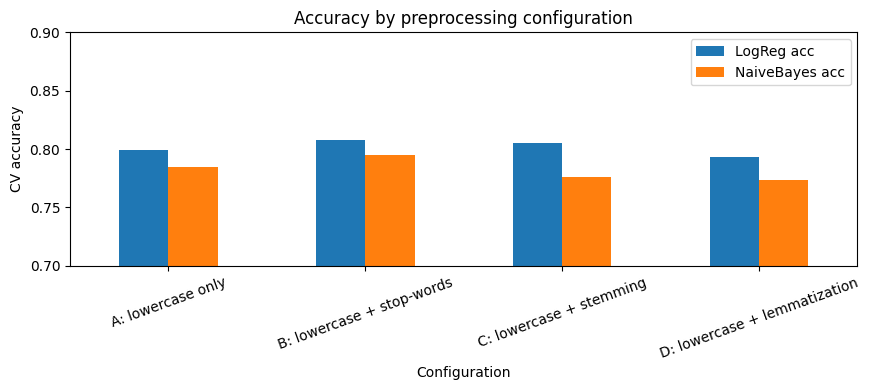

In [39]:
results7.set_index("Configuration")[["LogReg acc", "NaiveBayes acc"]].plot(kind="bar", figsize=(9, 4), ylim=(0.7, 0.9))
plt.title("Accuracy by preprocessing configuration"); plt.ylabel("CV accuracy"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

### Analysis (5–6 lines)
1. **Best accuracy:** configuration **B (lowercase + stop-word removal)** scored highest with both models
   (LogReg ≈ 80.8 %, Naive Bayes ≈ 79.5 %), followed by A and C; **D (lemmatization)** was lowest (≈ 79.3 % / 77.3 %).
2. **But the gaps are small** (≤ 1.5 points) and smaller than the fold-to-fold standard deviation (≈ 0.03), so on 1000 reviews the
   differences are **not statistically meaningful** — none of the configurations is clearly better.
3. **Vocabulary:** stemming cut the vocabulary by about 31 % (30,615 → 21,010) and lemmatization by about 25 % (→ 23,009), yet this
   did **not** improve accuracy; stop-word removal cut tokens per document by 46 % (631 → 342) while changing the vocabulary by only ~190 words.
4. **Why:** TF-IDF already down-weights very frequent words, and sentiment is expressed by many different word forms, so merging forms
   (especially for Naive Bayes, which dropped 1–2 points) can erase useful distinctions.
5. **Cost:** lemmatization took ~34 s versus under 1 s for the other steps, so for this task a cheap pipeline (lowercase + stop-words or stemming)
   is the better trade-off. *(Numbers are from my run; they may vary slightly with library versions.)*

---
# Task 8: Minimum Edit Distance (Levenshtein)
## 8.1 Recursive version (no memoization)

In [40]:
calls = 0
def lev_recursive(a, b):
    global calls
    calls += 1
    if not a: return len(b)
    if not b: return len(a)
    return min(lev_recursive(a[1:], b) + 1,                       # delete a[0]
               lev_recursive(a, b[1:]) + 1,                       # insert b[0]
               lev_recursive(a[1:], b[1:]) + (a[0] != b[0]))      # substitute / match

for a, b in [("kitten", "sitting"), ("sunday", "saturday"), ("intention", "execution")]:
    calls = 0; t0 = time.perf_counter()
    d = lev_recursive(a, b)
    print(f"{a:10s} -> {b:10s} distance={d}  recursive calls={calls:>9,}  time={time.perf_counter() - t0:.3f}s")

kitten     -> sitting    distance=3  recursive calls=   29,737  time=0.008s
sunday     -> saturday   distance=3  recursive calls=   60,121  time=0.018s
intention  -> execution  distance=5  recursive calls=2,193,844  time=0.566s


**Limitation:** the plain recursion recomputes the same sub-problems (`lev(a[i:], b[j:])`) again and again. The number of calls
grows exponentially (roughly 3^n), so strings of length 9 already need over a million calls and longer words become impractical.
Dynamic programming stores each sub-problem once, giving O(m·n) time.

## 8.2 Iterative dynamic programming + DP table

In [41]:
def lev_dp(a, b, sub_cost=1):
    m, n = len(a), len(b)
    D = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(1, m + 1): D[i][0] = i          # i deletions
    for j in range(1, n + 1): D[0][j] = j          # j insertions
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cost = 0 if a[i - 1] == b[j - 1] else sub_cost
            D[i][j] = min(D[i - 1][j] + 1,         # deletion
                          D[i][j - 1] + 1,         # insertion
                          D[i - 1][j - 1] + cost)  # substitution / match
    return D

def show_table(a, b, D):
    return pd.DataFrame(D, index=["#"] + list(a), columns=["#"] + list(b))

pairs = [("intention", "execution"), ("kitten", "sitting"), ("sunday", "saturday")]
for a, b in pairs:
    D = lev_dp(a, b)
    print(f"\n{a} -> {b}   (sub = 1)   distance = {D[-1][-1]}")
    display(show_table(a, b, D))


intention -> execution   (sub = 1)   distance = 5


,#,e,x,e,c,u,t,i,o,n
#,0,1,2,3,4,5,6,7,8,9
i,1,1,2,3,4,5,6,6,7,8
n,2,2,2,3,4,5,6,7,7,7
t,3,3,3,3,4,5,5,6,7,8
e,4,3,4,3,4,5,6,6,7,8
n,5,4,4,4,4,5,6,7,7,7
t,6,5,5,5,5,5,5,6,7,8
i,7,6,6,6,6,6,6,5,6,7
o,8,7,7,7,7,7,7,6,5,6
n,9,8,8,8,8,8,8,7,6,5



kitten -> sitting   (sub = 1)   distance = 3


,#,s,i,t,t,i,n,g
#,0,1,2,3,4,5,6,7
k,1,1,2,3,4,5,6,7
i,2,2,1,2,3,4,5,6
t,3,3,2,1,2,3,4,5
t,4,4,3,2,1,2,3,4
e,5,5,4,3,2,2,3,4
n,6,6,5,4,3,3,2,3



sunday -> saturday   (sub = 1)   distance = 3


,#,s,a,t,u,r,d,a,y
#,0,1,2,3,4,5,6,7,8
s,1,0,1,2,3,4,5,6,7
u,2,1,1,2,2,3,4,5,6
n,3,2,2,2,3,3,4,5,6
d,4,3,3,3,3,4,3,4,5
a,5,4,3,4,4,4,4,3,4
y,6,5,4,4,5,5,5,4,3


### Constructing a table by hand (kitten → sitting)
1. Write `#` + the letters of the source down the left side and `#` + the letters of the target along the top.
2. Fill the first row with 0,1,2,3… (insertions) and the first column with 0,1,2,3… (deletions).
3. For every other cell take `min( above+1 , left+1 , diagonal + (0 if the two letters are equal else 1) )`.
4. The bottom-right cell is the answer. Example: cell (k, s): above = 1, left = 1, diagonal = 0 + 1 (k≠s) → min(2, 2, 1) = **1**.

Expected distances (sub = 1): intention→execution = **5**, kitten→sitting = **3**, sunday→saturday = **3**. They match the tables printed above.

## 8.3 Backtrace and comparison with substitution cost = 2

In [42]:
def backtrace(a, b, D, sub_cost=1):
    i, j, ops = len(a), len(b), []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and D[i][j] == D[i - 1][j - 1] + (0 if a[i - 1] == b[j - 1] else sub_cost):
            if a[i - 1] == b[j - 1]:
                ops.append(("match", a[i - 1], a[i - 1], 0))
            else:
                ops.append(("substitute", a[i - 1], b[j - 1], sub_cost))
            i, j = i - 1, j - 1
        elif i > 0 and D[i][j] == D[i - 1][j] + 1:
            ops.append(("delete", a[i - 1], "-", 1)); i -= 1
        else:
            ops.append(("insert", "-", b[j - 1], 1)); j -= 1
    return ops[::-1]

def explain(a, b, sub_cost):
    D = lev_dp(a, b, sub_cost)
    ops = backtrace(a, b, D, sub_cost)
    total = sum(o[3] for o in ops)
    assert total == D[-1][-1]
    print(f"\n{a} -> {b}  (substitution cost = {sub_cost})  total cost = {total}")
    print("  " + " ".join(f"{o[1]:>2}" for o in ops))
    print("  " + " ".join(f"{o[2]:>2}" for o in ops))
    for o in ops:
        if o[0] != "match":
            print(f"   {o[0]:10s} {o[1]!r} -> {o[2]!r}   cost {o[3]}")
    return total

summary = []
for a, b in pairs:
    c1 = explain(a, b, 1)
    c2 = explain(a, b, 2)
    summary.append({"Pair": f"{a} -> {b}", "Cost (sub=1)": c1, "Cost (sub=2)": c2})
pd.DataFrame(summary)


intention -> execution  (substitution cost = 1)  total cost = 5
   i  n  t  e  n  t  i  o  n
   e  x  e  c  u  t  i  o  n
   substitute 'i' -> 'e'   cost 1
   substitute 'n' -> 'x'   cost 1
   substitute 't' -> 'e'   cost 1
   substitute 'e' -> 'c'   cost 1
   substitute 'n' -> 'u'   cost 1

intention -> execution  (substitution cost = 2)  total cost = 8
   i  n  t  e  -  n  t  i  o  n
   -  e  x  e  c  u  t  i  o  n
   delete     'i' -> '-'   cost 1
   substitute 'n' -> 'e'   cost 2
   substitute 't' -> 'x'   cost 2
   insert     '-' -> 'c'   cost 1
   substitute 'n' -> 'u'   cost 2

kitten -> sitting  (substitution cost = 1)  total cost = 3
   k  i  t  t  e  n  -
   s  i  t  t  i  n  g
   substitute 'k' -> 's'   cost 1
   substitute 'e' -> 'i'   cost 1
   insert     '-' -> 'g'   cost 1

kitten -> sitting  (substitution cost = 2)  total cost = 5
   k  i  t  t  e  n  -
   s  i  t  t  i  n  g
   substitute 'k' -> 's'   cost 2
   substitute 'e' -> 'i'   cost 2
   insert     '-' -> 'g'  

,Pair,Cost (sub=1),Cost (sub=2)
0,intention -> execution,5,8
1,kitten -> sitting,3,5
2,sunday -> saturday,3,4


**Comparison:** with substitution = 2, a substitution costs the same as one deletion + one insertion, so it is never cheaper to substitute
than to delete and insert (the backtrace for *intention → execution* now uses `delete i` and `insert c` as well as substitutions). All distances increase
(intention→execution **5 → 8**, kitten→sitting **3 → 5**, sunday→saturday **3 → 4**). The Jurafsky–Martin
version (sub = 2) is also the Levenshtein *alignment* distance used for tasks such as speech-recognition WER.

---
# Task 9: Spelling Correction with Edit Distance

In [43]:
from nltk.corpus import brown
freq = Counter(w.lower() for w in brown.words() if w.isalpha() and len(w) > 1)
vocab = {w: c for w, c in freq.items() if c >= 2}       # drop one-off typos / hapaxes
vocab_by_len = {}
for w in vocab:
    vocab_by_len.setdefault(len(w), []).append(w)
print("Dictionary size:", len(vocab), "words (Brown corpus, freq >= 2)")
print("Most frequent:", [w for w, _ in Counter(vocab).most_common(8)])

Dictionary size: 24841 words (Brown corpus, freq >= 2)
Most frequent: ['the', 'of', 'and', 'to', 'in', 'that', 'is', 'was']


In [44]:
def edit_distance(a, b, limit=99):
    """Levenshtein distance with sub=insert=delete=1 (two-row DP)."""
    if abs(len(a) - len(b)) > limit: return limit + 1
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def candidates(word, max_len_diff=3):
    return [w for L in range(len(word) - max_len_diff, len(word) + max_len_diff + 1) for w in vocab_by_len.get(L, [])]

def suggest(word, k=5, use_freq=False):
    """Top-k closest dictionary words. use_freq=True breaks distance ties with word frequency."""
    word = word.lower()
    scored = [(edit_distance(word, w), w) for w in candidates(word)]
    if use_freq:
        scored.sort(key=lambda x: (x[0], -vocab[x[1]]))       # nearest, then most frequent
    else:
        scored.sort(key=lambda x: (x[0], x[1]))               # nearest, then alphabetical (arbitrary)
    return [(w, d) for d, w in scored[:k]]

print(suggest("recieve", k=5))
print(suggest("recieve", k=5, use_freq=True))

[('relieve', 1), ('believe', 2), ('recede', 2), ('receive', 2), ('recipe', 2)]
[('relieve', 1), ('believe', 2), ('receive', 2), ('relieved', 2), ('revive', 2)]


In [45]:
tests = {
    "recieve": "receive", "definately": "definitely", "acommodate": "accommodate", "seperate": "separate",
    "occured": "occurred", "untill": "until", "wich": "which", "beleive": "believe", "adress": "address",
    "goverment": "government", "enviroment": "environment", "necesary": "necessary", "tommorow": "tomorrow",
    "freind": "friend", "thier": "their", "becuase": "because", "begining": "beginning", "writting": "writing",
    "sucessful": "successful", "wierd": "weird",
}
missing = [c for c in tests.values() if c not in vocab]
print("Correct words missing from dictionary:", missing)
tests = {m: c for m, c in tests.items() if c in vocab}
print(len(tests), "usable test words")

rows, hit_plain, hit_freq = [], 0, 0
for miss, gold in tests.items():
    p = suggest(miss, k=5)
    f = suggest(miss, k=5, use_freq=True)
    hit_plain += p[0][0] == gold
    hit_freq  += f[0][0] == gold
    rows.append({"Misspelled": miss, "Gold": gold,
                 "Top-1 (no freq)": p[0][0], "OK?": "✔" if p[0][0] == gold else "✘",
                 "Top-1 (freq tie-break)": f[0][0], "OK? ": "✔" if f[0][0] == gold else "✘",
                 "Top-5 (freq)": [w for w, _ in f]})
pd.DataFrame(rows)

Correct words missing from dictionary: []
20 usable test words


,Misspelled,Gold,Top-1 (no freq),OK?,Top-1 (freq tie-break),OK?,Top-5 (freq)
0,recieve,receive,relieve,✘,relieve,✘,"[relieve, believe, receive, relieved, revive]"
1,definately,definitely,definitely,✔,definitely,✔,"[definitely, delicately, definite, indefinitely, infinitely]"
2,acommodate,accommodate,accommodate,✔,accommodate,✔,"[accommodate, accommodates, commodity, commodore, commodities]"
3,seperate,separate,separate,✔,separate,✔,"[separate, operate, separated, desperate, generate]"
4,occured,occurred,occurred,✔,occurred,✔,"[occurred, occur, occupied, occurs, accused]"
5,untill,until,until,✔,until,✔,"[until, still, till, untie, untold]"
6,wich,which,rich,✘,with,✘,"[with, which, wish, rich, witch]"
7,beleive,believe,believe,✔,believe,✔,"[believe, receive, relive, leave, live]"
8,adress,address,address,✔,address,✔,"[address, dress, across, areas, press]"
9,goverment,government,government,✔,government,✔,"[government, movement, governments, movements, governmental]"


In [46]:
n = len(tests)
print(f"Top-1 accuracy, distance only          : {hit_plain}/{n} = {hit_plain / n:.0%}")
print(f"Top-1 accuracy, distance + frequency   : {hit_freq}/{n} = {hit_freq / n:.0%}")

Top-1 accuracy, distance only          : 13/20 = 65%
Top-1 accuracy, distance + frequency   : 15/20 = 75%


### Observations
* **Accuracy:** distance only = **13/20 = 65 %**; distance + frequency tie-break = **15/20 = 75 %** (+10 points).
  Frequency fixed `becuase → because` (`became` and `because` are tied) and `writting → writing`.
* **Remaining errors — mostly transpositions:** `recieve`, `freind`, `thier` and `wierd` are swaps of two neighbouring letters.
  Levenshtein counts a swap as **2 edits**, so a wrong word needing only 1 substitution wins (`recieve → relieve`). Using
  **Damerau–Levenshtein** (transposition = 1) would fix these.
* **Frequency is only a prior:** for `wich`, both `which` and `with` are 1 edit away and the more frequent `with` was chosen, which is wrong here.
  Context (neighbouring words) is needed for such cases.
* **Real-word errors (their/there):** `their`, `there`, `form`, `from`, `piece`, `peace` are all valid dictionary words, so their edit distance
  to the dictionary is **0** and the checker never flags them (e.g. *"I went to there house"*). Detecting them needs **context**, for example an
  n-gram / language model that compares P(house | their) with P(house | there), or confusion sets.

In [47]:
# Real-word errors are not caught
for w in ["their", "there", "form", "from", "piece", "peace"]:
    print(f"{w:6s} in dictionary: {w in vocab}   suggest -> {suggest(w, k=1, use_freq=True)}")
print("\nExample: 'I went to there house' -> every token is a valid dictionary word, so the checker reports no error.")

their  in dictionary: True   suggest -> [('their', 0)]
there  in dictionary: True   suggest -> [('there', 0)]
form   in dictionary: True   suggest -> [('form', 0)]
from   in dictionary: True   suggest -> [('from', 0)]
piece  in dictionary: True   suggest -> [('piece', 0)]
peace  in dictionary: True   suggest -> [('peace', 0)]

Example: 'I went to there house' -> every token is a valid dictionary word, so the checker reports no error.
